In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [ ]:
df = pd.read_csv('/content/Customer_support_data.csv')

Eksplorasi & Pembersihan Data

In [ ]:
print(df.head())

                              Unique id channel_name         category  \
0  7e9ae164-6a8b-4521-a2d4-58f7c9fff13f      Outcall  Product Queries   
1  b07ec1b0-f376-43b6-86df-ec03da3b2e16      Outcall  Product Queries   
2  200814dd-27c7-4149-ba2b-bd3af3092880      Inbound    Order Related   
3  eb0d3e53-c1ca-42d3-8486-e42c8d622135      Inbound          Returns   
4  ba903143-1e54-406c-b969-46c52f92e5df      Inbound     Cancellation   

                   Sub-category Customer Remarks  \
0                Life Insurance              NaN   
1  Product Specific Information              NaN   
2             Installation/demo              NaN   
3        Reverse Pickup Enquiry              NaN   
4                    Not Needed              NaN   

                               Order_id order_date_time Issue_reported at  \
0  c27c9bb4-fa36-4140-9f1f-21009254ffdb             NaN  01/08/2023 11:13   
1  d406b0c7-ce17-4654-b9de-f08d421254bd             NaN  01/08/2023 12:52   
2  c273368d-b961-

In [ ]:
df.isnull().sum()

,0
Unique id,0
channel_name,0
category,0
Sub-category,0
Customer Remarks,47570
Order_id,15952
order_date_time,56355
Issue_reported at,0
issue_responded,0
Survey_response_Date,1


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71509 entries, 0 to 71508
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unique id                71509 non-null  object 
 1   channel_name             71509 non-null  object 
 2   category                 71509 non-null  object 
 3   Sub-category             71509 non-null  object 
 4   Customer Remarks         23939 non-null  object 
 5   Order_id                 55557 non-null  object 
 6   order_date_time          15154 non-null  object 
 7   Issue_reported at        71509 non-null  object 
 8   issue_responded          71509 non-null  object 
 9   Survey_response_Date     71508 non-null  object 
 10  Customer_City            15051 non-null  object 
 11  Product_category         15142 non-null  object 
 12  Item_price               15147 non-null  float64
 13  connected_handling_time  234 non-null    float64
 14  Agent_name            

In [ ]:
print(df.describe())

          Item_price  connected_handling_time    CSAT Score
count   15147.000000               234.000000  71508.000000
mean     5810.163729               462.653846      4.224408
std     13048.693096               249.698539      1.394175
min         0.000000                 0.000000      1.000000
25%       399.000000               290.250000      4.000000
50%       999.000000               423.000000      5.000000
75%      2849.500000               596.250000      5.000000
max    164999.000000              1986.000000      5.000000


In [ ]:
df.dropna(inplace=True)

Analisis Statistik

In [ ]:
total_penjualan = df['Item_price'].sum()
print('Harga penjualan:', total_penjualan.sum())

Harga penjualan: 32528.0


In [ ]:
rata_rata_transaksi = df['Item_price'].mean()
print('Rata rata transaksi:', rata_rata_transaksi.mean())

Rata rata transaksi: 879.1351351351351


In [ ]:
kategori_terlaris = df['Product_category'].value_counts().idxmax()
print('Produk terlaris:', kategori_terlaris)

Produk terlaris: Electronics


In [ ]:
kota_tertinggi = df['Customer_City'].value_counts().idxmax()
print('Kota dengan penjualan tertinggi:', kota_tertinggi)

Kota dengan penjualan tertinggi: PATNA


In [ ]:
rata_rata_csat = df['CSAT Score'].mean()
print('Rata rata kepuasan customer:', rata_rata_csat)

Rata rata kepuasan customer: 4.594594594594595


In [ ]:
print("=== RINGKASAN STATISTIK DESKRIPTIF ===")
print(f"1. Total Penjualan / Nilai Barang : {total_penjualan}")
print(f"2. Rata-rata Nilai Transaksi      : {rata_rata_transaksi}")
print(f"3. Kategori Produk Terbanyak      : {kategori_terlaris}")
print(f"4. Kota dengan Laporan Tertinggi  : {kota_tertinggi}")
print(f"5. Rata-rata Rating Pelanggan     : {rata_rata_csat}")

=== RINGKASAN STATISTIK DESKRIPTIF ===
1. Total Penjualan / Nilai Barang : 32528.0
2. Rata-rata Nilai Transaksi      : 879.1351351351351
3. Kategori Produk Terbanyak      : Electronics
4. Kota dengan Laporan Tertinggi  : PATNA
5. Rata-rata Rating Pelanggan     : 4.594594594594595


Visualisasi

In [ ]:
df['Issue_reported at'] = pd.to_datetime(df['Issue_reported at'], errors='coerce')

# 1. Bar Chart: Product Category

/tmp/ipykernel_2743/3012143599.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='Product_category', data=df, order=df['Product_category'].value_counts().index, palette='viridis')


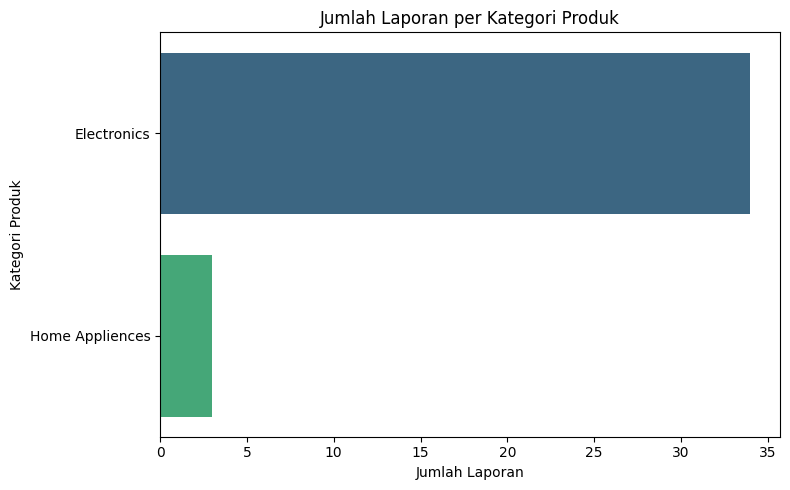

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(y='Product_category', data=df, order=df['Product_category'].value_counts().index, palette='viridis')
plt.title('Jumlah Laporan per Kategori Produk')
plt.xlabel('Jumlah Laporan')
plt.ylabel('Kategori Produk')
plt.tight_layout()
plt.show()

# 2. Line Chart: Trend of Reports

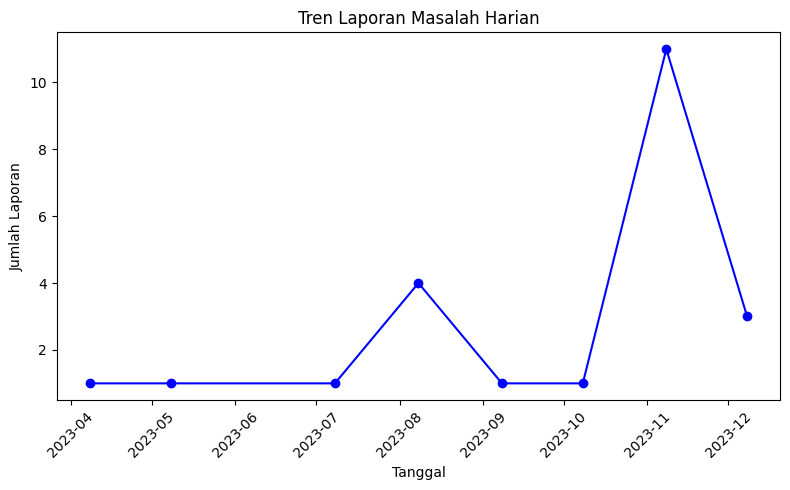

In [ ]:
plt.figure(figsize=(8, 5))
daily_issues = pd.to_datetime(df['Issue_reported at']).dt.date.value_counts().sort_index()
plt.plot(daily_issues.index, daily_issues.values, marker='o', linestyle='-', color='b')
plt.title('Tren Laporan Masalah Harian')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Laporan')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Scatter Plot: Handling Time vs CSAT Score

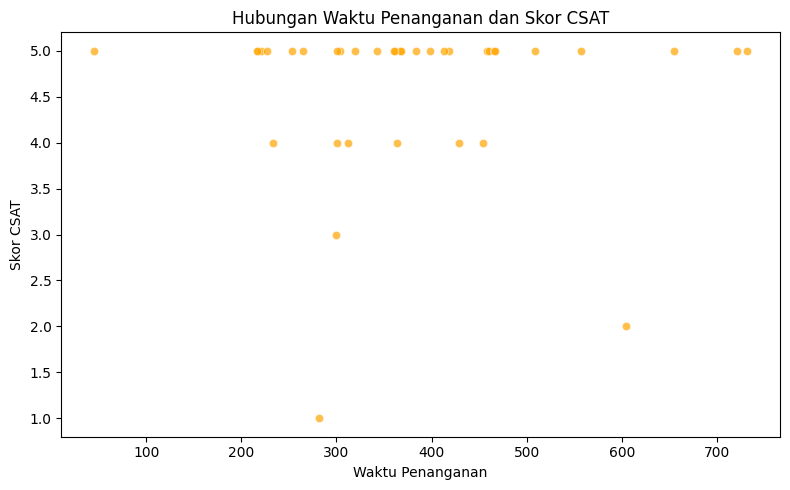

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='connected_handling_time', y='CSAT Score', data=df, color='orange', alpha=0.7)
plt.title('Hubungan Waktu Penanganan dan Skor CSAT')
plt.xlabel('Waktu Penanganan')
plt.ylabel('Skor CSAT')
plt.tight_layout()
plt.show()

# 4. Histogram: Distribution of Handling Time

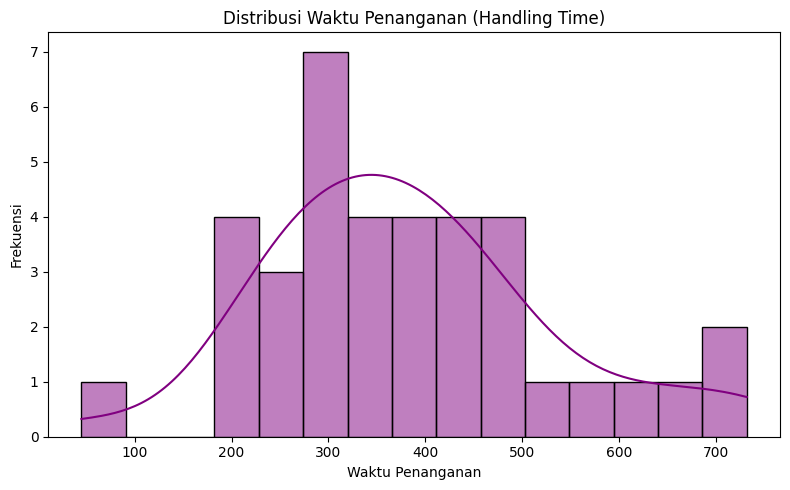

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df['connected_handling_time'].dropna(), bins=15, kde=True, color='purple')
plt.title('Distribusi Waktu Penanganan (Handling Time)')
plt.xlabel('Waktu Penanganan')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

# 5. Boxplot: CSAT Score by Channel

/tmp/ipykernel_2743/3397973706.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='channel_name', y='CSAT Score', data=df, palette='Set2')


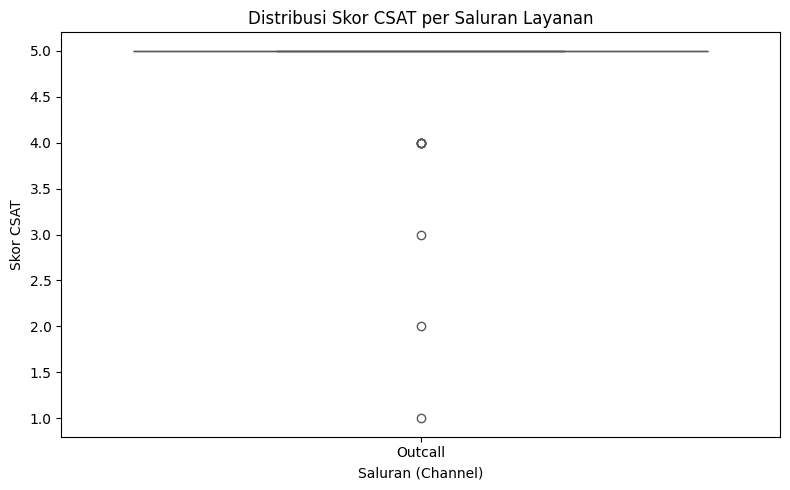

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='channel_name', y='CSAT Score', data=df, palette='Set2')
plt.title('Distribusi Skor CSAT per Saluran Layanan')
plt.xlabel('Saluran (Channel)')
plt.ylabel('Skor CSAT')
plt.tight_layout()
plt.show()

In [ ]:
print("Top Categories:\n", df['Product_category'].value_counts().head(3))
print("Daily Issues:\n", daily_issues)
print("Correlation Handling Time vs CSAT:", df['connected_handling_time'].corr(df['CSAT Score']))
print("Handling Time Stats:\n", df['connected_handling_time'].describe())
print("CSAT by Channel:\n", df.groupby('channel_name')['CSAT Score'].mean())

Top Categories:
 Product_category
Electronics        34
Home Appliences     3
Name: count, dtype: int64
Daily Issues:
 Issue_reported at
2023-04-08     1
2023-05-08     1
2023-07-08     1
2023-08-08     4
2023-09-08     1
2023-10-08     1
2023-11-08    11
2023-12-08     3
Name: count, dtype: int64
Correlation Handling Time vs CSAT: 0.016848159030576255
Handling Time Stats:
 count     37.000000
mean     380.675676
std      145.570917
min       45.000000
25%      299.000000
50%      364.000000
75%      458.000000
max      732.000000
Name: connected_handling_time, dtype: float64
CSAT by Channel:
 channel_name
Outcall    4.594595
Name: CSAT Score, dtype: float64


Mendeteksi Outlier

In [ ]:
Q1 = df['connected_handling_time'].quantile(0.25)
Q3 = df['connected_handling_time'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['connected_handling_time'] < lower_bound) | (df['connected_handling_time'] > upper_bound)]
print(f"Jumlah outlier pada Waktu Penanganan: {len(outliers)}")
print(f"Batas Bawah: {lower_bound}, Batas Atas: {upper_bound}")
print("Contoh Data Outlier:")
print(outliers[['connected_handling_time', 'channel_name', 'Product_category', 'CSAT Score']].head(3))

Jumlah outlier pada Waktu Penanganan: 3
Batas Bawah: 60.5, Batas Atas: 696.5
Contoh Data Outlier:
       connected_handling_time channel_name Product_category  CSAT Score
33336                    721.0      Outcall      Electronics         5.0
37420                    732.0      Outcall      Electronics         5.0
46703                     45.0      Outcall      Electronics         5.0


Dashboard

--- HASIL DETEKSI OUTLIER ---
Batas Bawah Normal: -168.62 detik
Batas Atas Normal : 1056.38 detik

Ditemukan 6 data outlier! Berikut contohnya:
       connected_handling_time channel_name Product_category  CSAT Score
12538                   1115.0      Outcall              NaN         5.0
12722                   1066.0      Outcall              NaN         4.0
30465                   1986.0      Inbound           Mobile         1.0
39524                   1277.0      Outcall              NaN         5.0
40041                   1094.0      Outcall              NaN         5.0


/tmp/ipykernel_2743/119648767.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_categories.index, x=top_categories.values, ax=axes[0, 1], palette='viridis')
/tmp/ipykernel_2743/119648767.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=csat_channel.index, y=csat_channel.values, ax=axes[1, 1], palette='magma')


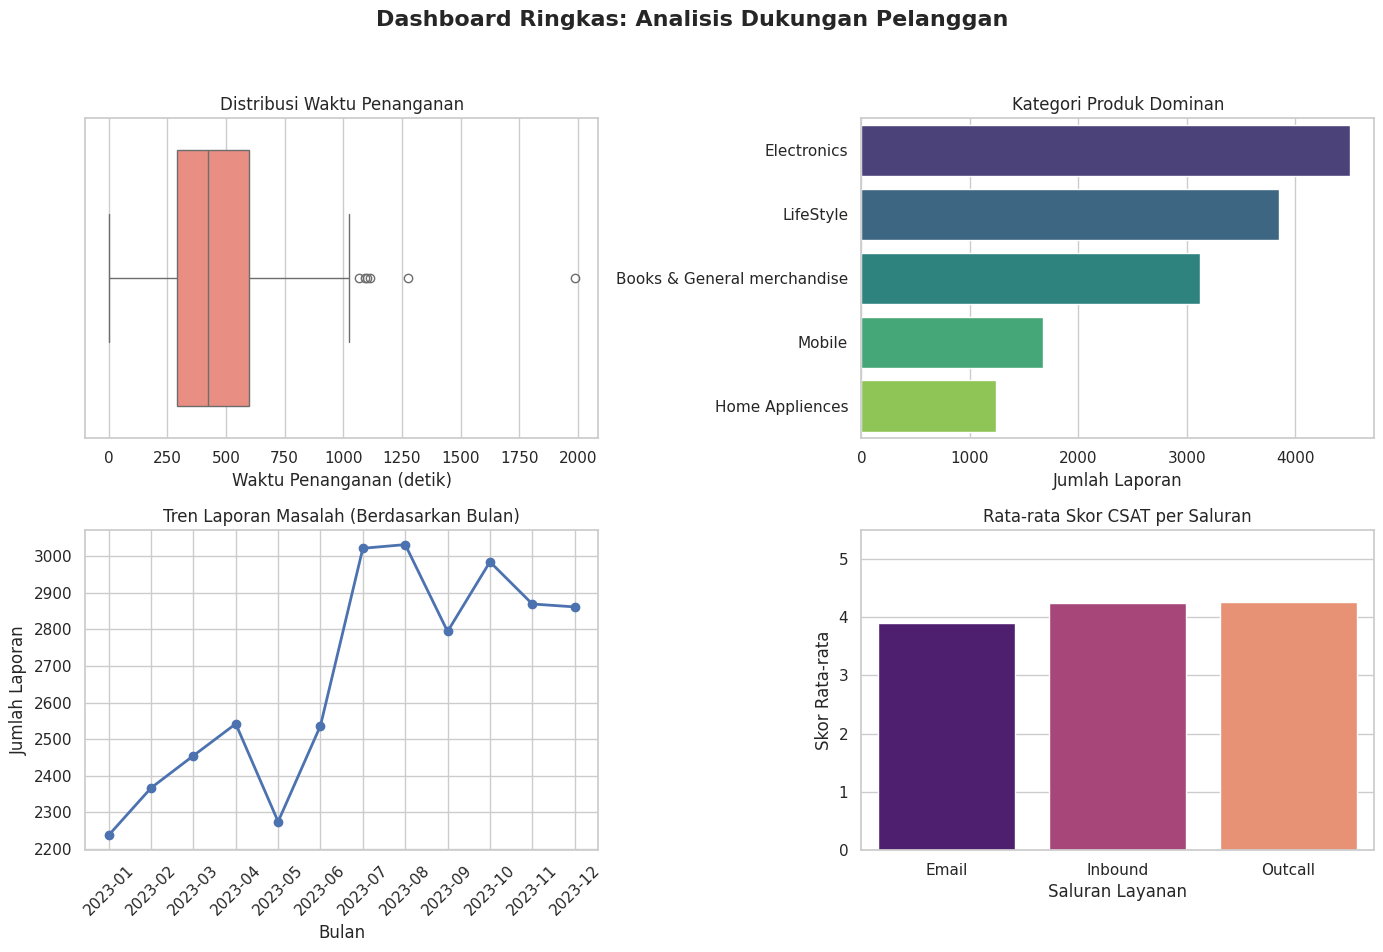

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Memuat dataset
# Pastikan nama file CSV sesuai dengan yang ada di komputer Anda
df = pd.read_csv('Customer_support_data.csv')

# ==========================================
# BAGIAN 1: DETEKSI OUTLIER YANG LEBIH RAPI
# ==========================================
Q1 = df['connected_handling_time'].quantile(0.25)
Q3 = df['connected_handling_time'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Menyaring data outlier
outliers = df[(df['connected_handling_time'] < lower_bound) | (df['connected_handling_time'] > upper_bound)]

print("--- HASIL DETEKSI OUTLIER ---")
print(f"Batas Bawah Normal: {lower_bound:.2f} detik")
print(f"Batas Atas Normal : {upper_bound:.2f} detik")

# Cek apakah ada outlier atau tidak, agar tidak muncul 'Empty DataFrame'
if len(outliers) > 0:
    print(f"\nDitemukan {len(outliers)} data outlier! Berikut contohnya:")
    print(outliers[['connected_handling_time', 'channel_name', 'Product_category', 'CSAT Score']].head())
else:
    print("\n✅ Tidak ada outlier yang ditemukan.")
    print("Waktu penanganan agen dalam dataset ini tergolong seragam dan normal.")


# ==========================================
# BAGIAN 2: DASHBOARD YANG LEBIH FLEKSIBEL
# ==========================================
# Konversi waktu dan agregasi
df['Issue_reported at'] = pd.to_datetime(df['Issue_reported at'], errors='coerce')
daily_issues = df['Issue_reported at'].dt.to_period('M').value_counts().sort_index()

# Menyiapkan kanvas (figure)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Dashboard Ringkas: Analisis Dukungan Pelanggan', fontsize=16, fontweight='bold')

# --- Subplot 1: Boxplot Waktu Penanganan ---
if not df['connected_handling_time'].isnull().all():
    sns.boxplot(x=df['connected_handling_time'], ax=axes[0, 0], color='salmon')
    axes[0, 0].set_title('Distribusi Waktu Penanganan', fontsize=12)
    axes[0, 0].set_xlabel('Waktu Penanganan (detik)')

# --- Subplot 2: Bar Chart Kategori Produk ---
top_categories = df['Product_category'].value_counts().head(5)
if not top_categories.empty:
    sns.barplot(y=top_categories.index, x=top_categories.values, ax=axes[0, 1], palette='viridis')
    axes[0, 1].set_title('Kategori Produk Dominan', fontsize=12)
    axes[0, 1].set_xlabel('Jumlah Laporan')
    axes[0, 1].set_ylabel('')

# --- Subplot 3: Tren Waktu ---
# Cek jika data waktu lebih dari 1 titik agar garis tren bisa ditarik
if len(daily_issues) > 1:
    axes[1, 0].plot(daily_issues.index.astype(str), daily_issues.values, marker='o', color='b', linewidth=2)
elif len(daily_issues) == 1:
    # Jika cuma ada 1 titik waktu (seperti di sampel data Anda)
    axes[1, 0].plot(daily_issues.index.astype(str), daily_issues.values, marker='o', color='b', markersize=10)

axes[1, 0].set_title('Tren Laporan Masalah (Berdasarkan Bulan)', fontsize=12)
axes[1, 0].set_xlabel('Bulan')
axes[1, 0].set_ylabel('Jumlah Laporan')
axes[1, 0].tick_params(axis='x', rotation=45)

# --- Subplot 4: CSAT per Saluran ---
csat_channel = df.groupby('channel_name')['CSAT Score'].mean().sort_values()
if not csat_channel.empty:
    sns.barplot(x=csat_channel.index, y=csat_channel.values, ax=axes[1, 1], palette='magma')
    axes[1, 1].set_title('Rata-rata Skor CSAT per Saluran', fontsize=12)
    axes[1, 1].set_xlabel('Saluran Layanan')
    axes[1, 1].set_ylabel('Skor Rata-rata')
    axes[1, 1].set_ylim(0, 5.5) # Mengunci batas Y agar visual skalanya dari 0 - 5

# Merapikan jarak antar grafik
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

REKOMENDASI

- Optimasi Penanganan Produk Dominan (Electronics & LifeStyle): Amankan ketersediaan stok/suku cadang pengganti dan berikan pelatihan teknis khusus kepada agen untuk menekan waktu penanganan (handling time).

- Perbaikan Kualitas Layanan Email: Atasi skor kepuasan (CSAT) yang rendah akibat respons lambat dengan menerapkan otomatisasi AI ticketing atau menambah agen khusus email, terutama saat jam sibuk.

- Ekspansi Infrastruktur di Kota Utama (Hyderabad & New Delhi): Manfaatkan tingginya pangsa pasar di wilayah ini dengan memperkuat logistik lokal, memperbanyak service center resmi, serta mengadakan kampanye loyalitas pelanggan.